<a href="https://colab.research.google.com/github/sharasunilkottari-pixel/SDAV_Lab/blob/main/Program1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import itertools

In [2]:
np.random.seed(42)

# **PART 1A: Classical Probability**

In [3]:
coin_space = ['H', 'T']
two_coin = list(itertools.product(coin_space, coin_space))
print('Sample Space:', two_coin)

Sample Space: [('H', 'H'), ('H', 'T'), ('T', 'H'), ('T', 'T')]


In [4]:
two_heads = [s for s in two_coin if s.count('H') == 2]
P_2H = len(two_heads) / len(two_coin)
print(f'P(2 Heads) = {P_2H}')

P(2 Heads) = 0.25


# **PART 1A — Dice Addition Rule**

In [5]:
# Dice - Addition Rule
dice = list(range(1, 7))
A = [x for x in dice if x % 2 == 0]
B = [x for x in dice if x > 3]
P_A = len(A)/6;  P_B = len(B)/6
P_AB = len(set(A)&set(B))/6
print(f'P(A∪B) = P(A)+P(B)-P(A∩B) = {P_A+P_B-P_AB:.4f}')

P(A∪B) = P(A)+P(B)-P(A∩B) = 0.6667


# **PART 1B: Empirical Probability**

In [6]:
for n in [10, 100, 1000, 10000]:
    tosses = np.random.binomial(1, 0.5, n)
    print(f'n={n:>6}: P(H)={tosses.mean():.4f}')

n=    10: P(H)=0.6000
n=   100: P(H)=0.4500
n=  1000: P(H)=0.5050
n= 10000: P(H)=0.4940


# **PART 1C: Bayes' Theorem**

In [7]:
P_Disease = 0.01    # Only 1% of the population has the disease.
P_Pos_D   = 0.99    # Sensitivity - If a person has the disease, the probability that the test is positive is 99%.
P_Pos_ND  = 0.05    # False Positive Rate - If a person does NOT have the disease, there is still a 5% probability that the test is positive.


# Total Probability
P_Pos = P_Pos_D*P_Disease + P_Pos_ND*(1-P_Disease)
# Bayes' Theorem
P_D_Pos = (P_Pos_D * P_Disease) / P_Pos
print(f'P(Disease | Positive) = {P_D_Pos:.4f} ({P_D_Pos*100:.2f}%)')

P(Disease | Positive) = 0.1667 (16.67%)


# **PART 2: Visualization**

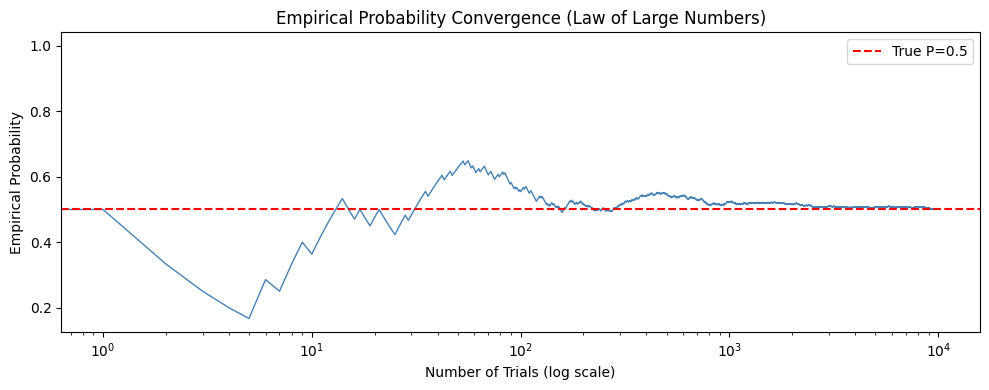

In [12]:
n_total = 10000
tosses  = np.random.binomial(1, 0.5, n_total)
emp_prob = [tosses[:i].mean() for i in range(1, n_total+1)]
plt.figure(figsize=(10,4))
plt.plot(emp_prob, color='steelblue', linewidth=1)
plt.axhline(0.5, color='red', linestyle='--', label='True P=0.5')
plt.xscale('log')
plt.title('Empirical Probability Convergence (Law of Large Numbers)')
plt.xlabel('Number of Trials (log scale)')
plt.ylabel('Empirical Probability')
plt.legend(); plt.tight_layout(); plt.show()